### Common libraries and `mpl` settings

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from cmcrameri import cm as cmc
from matplotlib.lines import Line2D

MM = 1.0 / 25.4
WIDTH_1COL = 90 * MM

mpl.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.fallback": "stix",
        "font.size": 9,
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "legend.fontsize": 9,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "axes.linewidth": 1.0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "legend.frameon": False,
        "axes.grid": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

out_folder = Path.cwd() / "figures"
out_folder.mkdir(exist_ok=True)

porosity_cases = [
    ("phi003", 3),
    ("phi006", 6),
    ("phi009", 9),
    ("phi012", 12),
]

filling_cases = [
    ("he1", 1),
    ("he2", 2),
]

bubble_cases = [
    ("phi006", 0.15),
    ("phi006_df023", 0.23),
    ("phi006_df030", 0.30),
]

porosity_colors = cmc.batlow(np.linspace(0.12, 0.82, 4))
filling_colors = cmc.batlow(np.linspace(0.28, 0.68, 2))
bubble_colors = cmc.batlow(np.linspace(0.18, 0.72, 3))

## Data preparation from MD
Run the following extraction cells only when the complete MD calculation results are available in `single_fiber/heat/results/`. The plotting cells below use only `pp_data/`.

In [3]:
root = Path("../single_fiber/heat/results/TMB")
pp = Path("pp_data")
pp.mkdir(exist_ok=True)
seeds = range(42, 52)
alphas = [25, 50, 75, 100, 200, 400, 800]

### Figure 4 - He-release times
Save the normalised histogram of first-crossing times for each seed and the remaining inventory at connectivity loss.

In [4]:
bins = np.linspace(0.0, 1.02, 86)
xc = 0.5 * (bins[:-1] + bins[1:])
hist_rows = []
remaining_rows = []

for alpha in alphas:
    for seed in seeds:
        run = root / "phi006" / f"s{seed}" / "he2" / f"alpha_{alpha:.1f}"
        he = pd.read_csv(run / "he_release.txt", sep=r"\s+")
        off = pd.read_csv(run / "heat_off.txt", sep=r"\s+")
        heat = pd.read_csv(run / "heat.txt", sep=r"\s+", usecols=["NHe_box"])
        tc = off.time_ps.iloc[0]
        n0 = heat.NHe_box.iloc[0]
        tau = he.time_ps.to_numpy() / tc
        tau = tau[(tau >= 0.0) & (tau <= 1.02)]
        h, _ = np.histogram(tau, bins=bins)
        dens = h / h.sum() / np.diff(bins)
        hist_rows.extend((alpha, seed, x, y) for x, y in zip(xc, dens))
        remaining_rows.append((alpha, seed, 100 * (1 - (he.time_ps <= tc).sum() / n0)))

pd.DataFrame(hist_rows, columns=["alpha", "seed", "tau", "density"]).to_csv(
    pp / "he_release_histograms.csv.gz", index=False, compression="gzip"
)
pd.DataFrame(remaining_rows, columns=["alpha", "seed", "remaining_pct"]).to_csv(
    pp / "he_remaining.csv", index=False
)
print(f"Figure 4: {len(remaining_rows)} trajectories")

Figure 4: 70 trajectories


### Figure 5 — He-release fractions
Calculate the cumulative release fraction for each seed on a common normalised time grid.

In [5]:
tau_grid = np.linspace(0.0, 1.0, 401)
conditions = list(
    dict.fromkeys(
        [(case, "he2", alpha) for case, _ in porosity_cases for alpha in (100, 400)]
        + [
            ("phi006", state, alpha)
            for state, _ in filling_cases
            for alpha in (100, 400)
        ]
        + [(case, "he2", 400) for case, _ in bubble_cases]
    )
)
rows = []

for case, state, alpha in conditions:
    for seed in seeds:
        run = root / case / f"s{seed}" / state / f"alpha_{alpha:.1f}"
        he = pd.read_csv(run / "he_release.txt", sep=r"\s+")
        heat = pd.read_csv(run / "heat.txt", sep=r"\s+", usecols=["NHe_box"])
        off = pd.read_csv(run / "heat_off.txt", sep=r"\s+")
        tc = off.time_ps.iloc[0]
        n0 = heat.NHe_box.iloc[0]
        tau = np.sort(he.time_ps.to_numpy() / tc)
        f = np.searchsorted(tau, tau_grid, side="right") / n0
        rows.extend((case, state, alpha, seed, t, x) for t, x in zip(tau_grid, f))

pd.DataFrame(
    rows, columns=["case", "state", "alpha", "seed", "tau", "fraction"]
).to_csv(pp / "he_release_curves.csv.gz", index=False, compression="gzip")
print(f"Figure 5: {len(conditions) * len(seeds)} trajectories")

Figure 5: 120 trajectories


### Figure 6 — He kinetic energies
Calculate per-seed energy histograms and untruncated mean and total energies up to connectivity loss.

In [6]:
m_He = 4.002602
mvv2e = 1.0364269656262175e-4
alpha = 400.0
bins = np.linspace(0.0, 5.0, 121)
xc = 0.5 * (bins[:-1] + bins[1:])
hist_rows = []
rows = []

for case, p in porosity_cases:
    for seed in seeds:
        run = root / case / f"s{seed}" / "he2" / f"alpha_{alpha:.1f}"
        he = pd.read_csv(run / "he_release.txt", sep=r"\s+")
        off = pd.read_csv(run / "heat_off.txt", sep=r"\s+")
        he = he.loc[he.time_ps <= off.time_ps.iloc[0]]
        v = he[["vx_Aps", "vy_Aps", "vz_Aps"]].to_numpy()
        E = 0.5 * m_He * mvv2e * np.sum(v**2, axis=1)
        h, _ = np.histogram(E, bins=bins)
        dens = h / h.sum() / np.diff(bins)
        hist_rows.extend((p, seed, x, y) for x, y in zip(xc, dens))
        rows.append((p, seed, E.mean(), E.sum() / 1000, len(E)))

pd.DataFrame(hist_rows, columns=["p", "seed", "E_center", "density"]).to_csv(
    pp / "he_energy_histograms.csv.gz", index=False, compression="gzip"
)
pd.DataFrame(rows, columns=["p", "seed", "E_mean", "E_total_keV", "N_release"]).to_csv(
    pp / "he_energy_summary.csv", index=False
)
print(f"Figure 6: {len(rows)} trajectories")

Figure 6: 40 trajectories


## Figures from processed data

### Figure 4

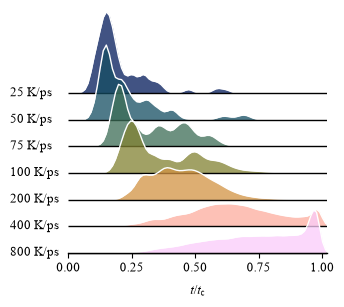

In [7]:
he_time = pd.read_csv("pp_data/he_release_histograms.csv.gz")
seeds = range(42, 52)
alphas = [25, 50, 75, 100, 200, 400, 800]
xc = np.sort(he_time.tau.unique())
cmap = cmc.batlow
profiles = []

for alpha in alphas:
    d = he_time.loc[he_time.alpha.eq(alpha)]
    y_all = d.pivot(index="seed", columns="tau", values="density").to_numpy()
    mean = gaussian_filter1d(y_all.mean(axis=0), sigma=1.3, mode="nearest")
    profiles.append((alpha, mean))

fig_He_release, ax = plt.subplots(figsize=(WIDTH_1COL, 80 * MM))

dy = 0.30
mx = max(mean.max() for _, mean in profiles)
scale = 0.92 / mx

nprof = len(profiles)
offsets = [(nprof - 1 - i) * dy for i in range(nprof)]
bottom_off = offsets[-1]

for i, ((alpha, mean), off) in enumerate(zip(profiles, offsets)):
    color = cmap(i / (nprof - 1))
    y = off + mean * scale

    z0 = 3 * i

    ax.fill_between(xc, off, y, color=color, linewidth=0, alpha=0.75, zorder=z0 + 1)

    ax.plot(xc, y, color="white", lw=1.0, zorder=z0 + 2)

    ax.hlines(off, 0.0, 1.02, color="black", lw=1.0, zorder=z0 + 3)

    ax.text(
        -0.225,
        off,
        f"{alpha} K/ps",
        transform=ax.get_yaxis_transform(),
        ha="left",
        va="center",
    )

ax.set_xlim(0.0, 1.02)
ax.set_ylim(bottom_off - 0.02, offsets[0] + 0.95)
ax.set_yticks([])

for spine in ["left", "right", "top"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_position(("data", bottom_off))
ax.spines["bottom"].set_linewidth(1.0)
ax.set_xticks(np.linspace(0.0, 1.0, 5))
ax.set_xlabel(r"$t/t_{\mathrm{c}}$", labelpad=8)

plt.tight_layout()

fig_He_release.savefig(out_folder / "He_release.pdf", pad_inches=0.05)

plt.show()

In [9]:
he_remaining = pd.read_csv("pp_data/he_remaining.csv")
print(he_remaining.groupby("alpha").remaining_pct.agg(["mean", "std"]).round(2))

        mean    std
alpha              
25      0.00   0.00
50      0.00   0.00
75      0.00   0.00
100     0.00   0.00
200     0.02   0.02
400     3.92   3.90
800    27.47  15.66


### Figure 5

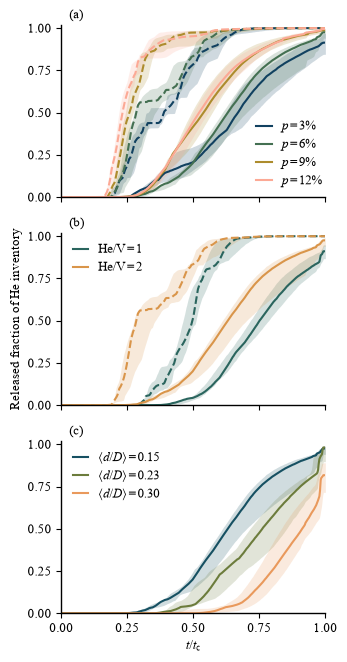

In [11]:
he_curves = pd.read_csv("pp_data/he_release_curves.csv.gz")
tau_grid = np.linspace(0.0, 1.0, 401)
styles = {100: "--", 400: "-"}


def ensemble_curve(case, state, alpha):
    d = he_curves.loc[
        he_curves.case.eq(case) & he_curves.state.eq(state) & he_curves.alpha.eq(alpha)
    ]
    curves = d.pivot(index="seed", columns="tau", values="fraction").to_numpy()
    return (
        np.median(curves, axis=0),
        np.percentile(curves, 25, axis=0),
        np.percentile(curves, 75, axis=0),
    )


fig_He_morph, ax = plt.subplots(
    3, 1, figsize=(WIDTH_1COL, 170 * MM), sharex=True, sharey=True
)

for color, (case, p) in zip(porosity_colors, porosity_cases):
    for alpha in [100, 400]:
        median, q25, q75 = ensemble_curve(case, "he2", alpha)

        ax[0].fill_between(tau_grid, q25, q75, color=color, alpha=0.2, linewidth=0)

        ax[0].plot(tau_grid, median, color=color, ls=styles[alpha], lw=1.5)

p_handles = [
    Line2D([0], [0], color=color, lw=1.5, label=rf"$p={p}\%$")
    for color, (_, p) in zip(porosity_colors, porosity_cases)
]

ax[0].legend(handles=p_handles, frameon=False, loc=(0.72, 0.025), handlelength=1.25)

for color, (state, filling) in zip(filling_colors, filling_cases):
    for alpha in [100, 400]:
        median, q25, q75 = ensemble_curve("phi006", state, alpha)

        ax[1].fill_between(tau_grid, q25, q75, color=color, alpha=0.2, linewidth=0)

        ax[1].plot(
            tau_grid,
            median,
            color=color,
            ls=styles[alpha],
            lw=1.5,
        )

fill_handles = [
    Line2D([0], [0], color=color, lw=1.5, label=rf"$\mathrm{{He/V}}={filling}$")
    for color, (_, filling) in zip(filling_colors, filling_cases)
]

ax[1].legend(handles=fill_handles, frameon=False, loc="upper left", handlelength=1.25)

for color, (case, dmean) in zip(bubble_colors, bubble_cases):
    median, q25, q75 = ensemble_curve(case, "he2", 400)

    ax[2].fill_between(tau_grid, q25, q75, color=color, alpha=0.2, linewidth=0)

    ax[2].plot(
        tau_grid,
        median,
        color=color,
        lw=1.5,
        label=rf"$\langle d/D\rangle={dmean:.2f}$",
    )

ax[2].legend(frameon=False, loc="upper left", handlelength=1.25)

for a in ax:
    a.set_xlim(0.0, 1.0)
    a.set_ylim(0.0, 1.02)
    a.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])

for a, label in zip(ax, ["(a)", "(b)", "(c)"]):
    a.text(0.03, 1.02, label, transform=a.transAxes, ha="left", va="bottom")

ax[1].set_ylabel("Released fraction of He inventory")
ax[2].set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
ax[2].set_xlabel(r"$t/t_{\mathrm{c}}$")

plt.tight_layout()

fig_He_morph.savefig(out_folder / "He_morph.pdf", pad_inches=0.05)

plt.show()

### Figure 6

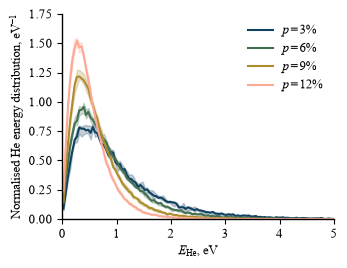

In [12]:
he_energy_hist = pd.read_csv("pp_data/he_energy_histograms.csv.gz")
xc = np.sort(he_energy_hist.E_center.unique())
fig_He_en, ax = plt.subplots(figsize=(WIDTH_1COL, 70 * MM))

for (_, p), color in zip(porosity_cases, porosity_colors):
    d = he_energy_hist.loc[he_energy_hist.p.eq(p)]
    dens = d.pivot(index="seed", columns="E_center", values="density").to_numpy()
    med = np.median(dens, axis=0)
    q25 = np.percentile(dens, 25, axis=0)
    q75 = np.percentile(dens, 75, axis=0)
    ax.plot(xc, med, lw=1.5, color=color, label=rf"$p={p}\%$")
    ax.fill_between(xc, q25, q75, color=color, alpha=0.25)

ax.set_xlim(0, 5)
ax.set_ylim(0, 1.75)
ax.set_xlabel(r"$E_\mathrm{He}$, eV")
ax.set_ylabel(r"Normalised He energy distribution, eV$^{-1}$")
ax.legend(frameon=False)

plt.tight_layout()
plt.show()
fig_He_en.savefig(out_folder / "he_energy_porosity.pdf", pad_inches=0.05)

In [13]:
energy = pd.read_csv("pp_data/he_energy_summary.csv")
print(
    energy.groupby("p")
    .agg(
        E_mean=("E_mean", "mean"),
        E_mean_std=("E_mean", "std"),
        E_total_keV=("E_total_keV", "mean"),
        E_total_std=("E_total_keV", "std"),
        N_release=("N_release", "mean"),
    )
    .round(3)
)

    E_mean  E_mean_std  E_total_keV  E_total_std  N_release
p                                                          
3    1.033       0.048        5.671        0.416     5507.8
6    0.832       0.037        9.721        0.613    11688.5
9    0.649       0.034       11.691        0.565    18024.3
12   0.514       0.020       12.409        0.500    24148.3
